# L2CS-Net: Gaze360 → MPIIGaze (Kaggle version), all 15 subjects

The Kaggle dataset is the **original MPIIGaze** (eye patches + full-frame `Original` images). L2CS-Net needs **normalized full-face crops**, so this notebook:

1. Downloads the dataset from Kaggle
2. Builds MPIIFaceGaze-style normalized face crops + (pitch, yaw) labels from `Data/Original` (head pose + camera calibration + 3D gaze target, using the Zhang et al. full-face normalization)
3. Fine-tunes the Gaze360 weights and saves `L2CSNet_mpiigaze_all15.pkl`

**Before running:** Runtime → Change runtime type → **GPU**. Have your Kaggle `kaggle.json` (kaggle.com → Settings → Create New Token) and the dataset slug (`owner/name` from the Kaggle URL).

⚠️ Step 2 relies on assumptions about the file layout (annotation columns, image ↔ line order, full-frame images). **Check the sanity-check plot in cell 5** before you spend time training.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("dhruv413/mpiigaze")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mpiigaze' dataset.
Path to dataset files: /kaggle/input/mpiigaze


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

destination = "/content/drive/MyDrive/GazeProject/MPIIGaze"
os.makedirs(os.path.dirname(destination), exist_ok=True)

if os.path.exists(destination):
    print("Destination already exists:", destination)
else:
    shutil.copytree(dataset_path, destination)

print("Copy complete!")
print("Files:", os.listdir(destination)[:10])

Destination already exists: /content/drive/MyDrive/GazeProject/MPIIGaze
Copy complete!
Files: ['MPIIGaze']


In [ ]:
#@title 1. Setup
import os, re, glob, math, time, shutil, random, numpy as np, cv2, torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
from scipy.io import loadmat
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
from google.colab import drive, files
print("torch", torch.__version__, "| GPU:", torch.cuda.is_available() and torch.cuda.get_device_name(0), "| CPUs:", os.cpu_count())
drive.mount('/content/drive')

torch 2.11.0+cu130 | GPU: Tesla T4 | CPUs: 2
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#@title 2. Config
KAGGLE_DATASET = "dhruv413/mpiigaze"   #@param {type:"string"}   # e.g. from kaggle.com/datasets/<owner>/<name>
SKIP_DOWNLOAD_IF_EXISTS = True          #@param {type:"boolean"}
OUT_DIR   = "/content/drive/MyDrive/l2cs_mpii_output"  #@param {type:"string"}
SAMPLES_PER_SUBJECT = 3000   #@param {type:"integer"}   # random subset per person (MPIIFaceGaze uses 3000); a few subjects have fewer
UNDISTORT = True             #@param {type:"boolean"}   # undistort with Calibration/Camera.mat before normalizing
EPOCHS      = 15     #@param {type:"integer"}
BATCH_SIZE  = 32     #@param {type:"integer"}
IMG_SIZE    = 448    #@param {type:"integer"}
LR_BACKBONE = 1e-5   #@param {type:"number"}
LR_HEAD     = 1e-4   #@param {type:"number"}
ALPHA       = 1.0    #@param {type:"number"}
VAL_SUBJECT = -1     #@param {type:"integer"}   # -1 = all 15 (final). 0..14 = hold one subject out to check error
NUM_BINS, BIN_W, OFFSET = 28, 3, 42
RAW_DIR, FACE_DIR = "/content/kaggle_mpiigaze", "/content/mpii_face"
os.makedirs(OUT_DIR, exist_ok=True)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
#@title 3. Download MPIIGaze from Kaggle
assert "OWNER" not in KAGGLE_DATASET, "Set KAGGLE_DATASET in the config cell"
if not (SKIP_DOWNLOAD_IF_EXISTS and os.path.isdir(RAW_DIR) and os.listdir(RAW_DIR)):
    if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        print("Upload your kaggle.json:")
        up = files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.move(list(up.keys())[0], os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    os.system(f"pip -q install kaggle")
    ret = os.system(f"kaggle datasets download -d {KAGGLE_DATASET} -p {RAW_DIR} --unzip")
    assert ret == 0, "Kaggle download failed - check the slug / credentials / that you accepted the dataset terms"
print(os.listdir(RAW_DIR))

Upload your kaggle.json:


Saving kaggle.json to kaggle.json
['MPIIGaze']


In [ ]:
#@title 4. Build normalized face crops + labels (takes several minutes)
F_NORM, D_NORM, NORM_SIZE, SAVE_SIZE = 960.0, 600.0, 448, 224

# --- locate Original/ and the 6-point face model
orig_root = next(d for d, ds, _ in os.walk(RAW_DIR) if os.path.basename(d) == "Original" and "p00" in ds)
subjects = sorted(d for d in os.listdir(orig_root) if re.fullmatch(r"p\d\d", d))
print("Original:", orig_root, "| subjects:", len(subjects))
assert len(subjects) == 15

FACE_MODEL = None
for f in glob.glob(RAW_DIR + "/**/*.mat", recursive=True):
    if "face" in os.path.basename(f).lower() and "model" in os.path.basename(f).lower():
        m = loadmat(f)
        for k, v in m.items():
            if not k.startswith("__") and np.asarray(v).shape in [(3, 6), (6, 3)]:
                FACE_MODEL = np.asarray(v, np.float64); FACE_MODEL = FACE_MODEL if FACE_MODEL.shape == (3, 6) else FACE_MODEL.T
                print("face model loaded from", f); break
    if FACE_MODEL is not None: break
if FACE_MODEL is None:
    print("WARNING: face-model .mat not found; using an approximate generic 6-point model (face center may be off by a few mm).")
    FACE_MODEL = np.array([[-45.0970, -21.3130, 21.3130, 45.0970, -26.2990, 26.2990],
                           [-0.4838, 0.4838, 0.4838, -0.4838, 68.5950, 68.5950],
                           [2.4851, 0, 0, 2.4851, -9.8649, -9.8649]])

# --- gather samples: annotation.txt line i <-> i-th sorted jpg of that day
random.seed(0)
tasks = []
for s in subjects:
    items = []
    for day in sorted(d for d in os.listdir(f"{orig_root}/{s}") if d.startswith("day")):
        imgs = sorted(glob.glob(f"{orig_root}/{s}/{day}/*.jpg"))
        ann_path = f"{orig_root}/{s}/{day}/annotation.txt"
        if not imgs or not os.path.exists(ann_path): continue
        ann = np.loadtxt(ann_path, ndmin=2)
        if len(ann) != len(imgs):
            print(f"  skip {s}/{day}: {len(imgs)} images vs {len(ann)} annotation lines"); continue
        items += [(s, day, p, a) for p, a in zip(imgs, ann)]
    random.shuffle(items)
    tasks += items[:SAMPLES_PER_SUBJECT]
    print(s, "available", len(items), "-> using", min(len(items), SAMPLES_PER_SUBJECT))

_cam = {}
def get_cam(s, shape):
    if s not in _cam:
        m = loadmat(f"{orig_root}/{s}/Calibration/Camera.mat")
        K = np.asarray(m["cameraMatrix"], np.float64); d = np.asarray(m["distCoeffs"], np.float64).ravel()
        maps = cv2.initUndistortRectifyMap(K, d, None, K, (shape[1], shape[0]), cv2.CV_16SC2) if UNDISTORT else None
        _cam[s] = (K, maps)
    return _cam[s]

def normalize_face(img, K, rvec, tvec, target):
    R = cv2.Rodrigues(np.asarray(rvec, np.float64).reshape(3, 1))[0]
    Fc = R @ FACE_MODEL + np.asarray(tvec, np.float64).reshape(3, 1)
    center = Fc.mean(axis=1); dist = np.linalg.norm(center)
    z = center / dist
    y = np.cross(z, R[:, 0]); y /= np.linalg.norm(y)
    x = np.cross(y, z); x /= np.linalg.norm(x)
    Rn = np.stack([x, y, z])
    S = np.diag([1., 1., D_NORM / dist])
    Cn = np.array([[F_NORM, 0, NORM_SIZE / 2], [0, F_NORM, NORM_SIZE / 2], [0, 0, 1.]])
    W = Cn @ S @ Rn @ np.linalg.inv(K)
    out = cv2.warpPerspective(img, W, (NORM_SIZE, NORM_SIZE))
    g = Rn @ (np.asarray(target, np.float64) - center); g /= np.linalg.norm(g)
    return out, float(np.arcsin(-g[1])), float(np.arctan2(-g[0], -g[2]))   # radians: pitch, yaw

def work(t):
    s, day, path, a = t
    img = cv2.imread(path)
    if img is None: return None
    K, maps = get_cam(s, img.shape)
    if maps is not None: img = cv2.remap(img, maps[0], maps[1], cv2.INTER_LINEAR)
    # annotation: [0:24] landmarks, [24:26] screen target, [26:29] 3D gaze target, [29:32] head rvec, [32:35] head tvec
    face, pitch, yaw = normalize_face(img, K, a[29:32], a[32:35], a[26:29])
    if abs(math.degrees(pitch)) >= OFFSET or abs(math.degrees(yaw)) >= OFFSET: return None   # outside +-42 deg range
    rel = f"Image/{s}/{day}_{os.path.basename(path)}"
    os.makedirs(os.path.dirname(f"{FACE_DIR}/{rel}"), exist_ok=True)
    cv2.imwrite(f"{FACE_DIR}/{rel}", cv2.resize(face, (SAVE_SIZE, SAVE_SIZE), interpolation=cv2.INTER_AREA), [cv2.IMWRITE_JPEG_QUALITY, 95])
    return s, rel, pitch, yaw

import multiprocessing as mp
shutil.rmtree(FACE_DIR, ignore_errors=True); os.makedirs(FACE_DIR + "/Label")
t0 = time.time(); res = []
with mp.Pool(os.cpu_count()) as pool:
    for i, r in enumerate(pool.imap(work, tasks, chunksize=32)):
        if r: res.append(r)
        if i % 5000 == 0: print(f"{i}/{len(tasks)}  ({time.time()-t0:.0f}s)")
for s in subjects:
    with open(f"{FACE_DIR}/Label/{s}.label", "w") as f:
        f.write("path pitch_rad yaw_rad\n")
        f.writelines(f"{rel} {p:.6f} {y:.6f}\n" for ss, rel, p, y in res if ss == s)
print(f"done: {len(res)} usable of {len(tasks)} in {time.time()-t0:.0f}s")

Original: /content/kaggle_mpiigaze/MPIIGaze/Data/Original | subjects: 15
face model loaded from /content/kaggle_mpiigaze/MPIIGaze/6 points-based face model.mat
p00 available 29961 -> using 3000
p01 available 24143 -> using 3000
p02 available 28019 -> using 3000
p03 available 35075 -> using 3000
p04 available 16831 -> using 3000
p05 available 16577 -> using 3000
p06 available 18448 -> using 3000
p07 available 15509 -> using 3000
p08 available 10701 -> using 3000
p09 available 7995 -> using 3000
p10 available 2810 -> using 2810
p11 available 2982 -> using 2982
p12 available 1609 -> using 1609
p13 available 1498 -> using 1498
p14 available 1500 -> using 1500
0/40399  (1s)
5000/40399  (48s)
10000/40399  (92s)
15000/40399  (136s)
20000/40399  (181s)
25000/40399  (224s)
30000/40399  (268s)
35000/40399  (311s)
40000/40399  (354s)
done: 40397 usable of 40399 in 357s


{'p00': 3000, 'p01': 3000, 'p02': 3000, 'p03': 3000, 'p04': 3000, 'p05': 3000, 'p06': 3000, 'p07': 2999, 'p08': 3000, 'p09': 3000, 'p10': 2809, 'p11': 2982, 'p12': 1609, 'p13': 1498, 'p14': 1500}
pitch mean/std: -10.5 / 6.5 | yaw mean/std: -0.0 / 10.6 (deg)


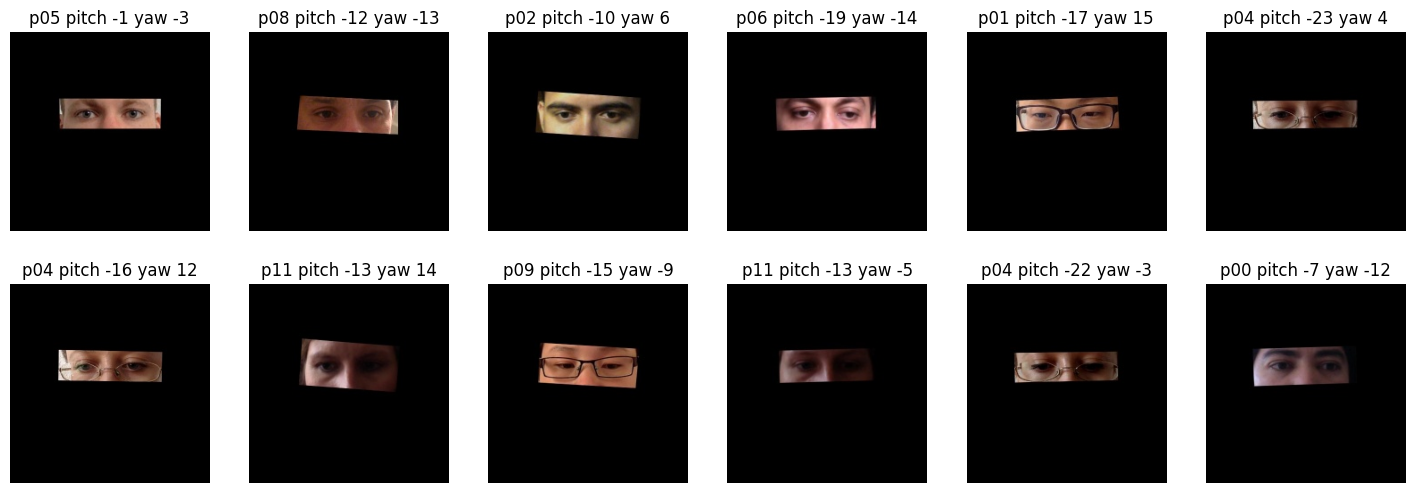

Expect: face roughly centered, upright, similar scale in every crop; labels mostly within about +-30 deg. If crops look wrong, STOP and send me this plot.


In [ ]:
#@title 5. SANITY CHECK - look at this before training!
import matplotlib.pyplot as plt
lab = {s: [l.split() for l in open(f"{FACE_DIR}/Label/{s}.label").read().splitlines()[1:]] for s in subjects}
print({s: len(v) for s, v in lab.items()})
allv = np.array([[float(r[1]), float(r[2])] for v in lab.values() for r in v]) * 180 / np.pi
print("pitch mean/std: %.1f / %.1f | yaw mean/std: %.1f / %.1f (deg)" % (allv[:,0].mean(), allv[:,0].std(), allv[:,1].mean(), allv[:,1].std()))
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for a_, (s, rel, p, y) in zip(ax.ravel(), random.sample(res, 12)):
    a_.imshow(cv2.cvtColor(cv2.imread(f"{FACE_DIR}/{rel}"), cv2.COLOR_BGR2RGB)); a_.axis("off")
    a_.set_title(f"{s} pitch {math.degrees(p):.0f} yaw {math.degrees(y):.0f}")
plt.show()
print("Expect: face roughly centered, upright, similar scale in every crop; labels mostly within about +-30 deg. If crops look wrong, STOP and send me this plot.")

In [ ]:
#@title 6. (Optional) Save processed data to Drive so you can skip steps 3-4 next time
shutil.make_archive(f"{OUT_DIR}/mpii_face_processed", "gztar", FACE_DIR); print("saved", f"{OUT_DIR}/mpii_face_processed.tar.gz")
# To reuse later:  !tar xzf /content/drive/MyDrive/l2cs_mpii_output/mpii_face_processed.tar.gz -C /content/mpii_face

saved /content/drive/MyDrive/l2cs_mpii_output/mpii_face_processed.tar.gz


In [ ]:
#@title 7. Get Gaze360 pretrained weights
cands = glob.glob("/content/**/L2CSNet_gaze360.pkl", recursive=True) + glob.glob("/content/drive/MyDrive/**/L2CSNet_gaze360.pkl", recursive=True)
if not cands:
    os.system("pip -q install gdown && gdown --folder https://drive.google.com/drive/folders/17p6ORr-JQJcw-eYtG2WGNiuS_qVKwdWd -O /content/weights")
    cands = glob.glob("/content/weights/**/L2CSNet_gaze360.pkl", recursive=True)
if not cands:
    print("Auto-download failed. Please upload L2CSNet_gaze360.pkl:")
    up = files.upload(); cands = ["/content/" + list(up.keys())[0]]
PRETRAINED = cands[0]; print("Using:", PRETRAINED)

Auto-download failed. Please upload L2CSNet_gaze360.pkl:


Saving L2CSNet_gaze360.pkl to L2CSNet_gaze360.pkl
Using: /content/L2CSNet_gaze360.pkl


In [ ]:
#@title 8. Dataset + model
class FaceSet(Dataset):
    def __init__(self, label_file, root, tf):
        self.root, self.tf, self.items = root, tf, []
        for ln in open(label_file).read().splitlines()[1:]:
            rel, p, y = ln.split(); self.items.append((rel, float(p) * 180 / np.pi, float(y) * 180 / np.pi))
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        rel, pitch, yaw = self.items[i]
        img = self.tf(Image.open(f"{self.root}/{rel}").convert("RGB"))
        bins = np.clip(np.digitize([pitch, yaw], np.arange(-OFFSET, OFFSET, BIN_W)) - 1, 0, NUM_BINS - 1)
        return img, torch.tensor(bins, dtype=torch.long), torch.tensor([pitch, yaw], dtype=torch.float32)

class L2CS(nn.Module):   # same layer names as official L2CS-Net
    def __init__(self, num_bins):
        super().__init__()
        r = torchvision.models.resnet50(weights=None)
        self.conv1, self.bn1, self.relu, self.maxpool = r.conv1, r.bn1, r.relu, r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc_yaw_gaze = nn.Linear(2048, num_bins)
        self.fc_pitch_gaze = nn.Linear(2048, num_bins)
    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = torch.flatten(self.avgpool(x), 1)
        return self.fc_yaw_gaze(x), self.fc_pitch_gaze(x)

tf = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
label_files = sorted(glob.glob(FACE_DIR + "/Label/p*.label"))
train_sets = [FaceSet(f, FACE_DIR, tf) for i, f in enumerate(label_files) if i != VAL_SUBJECT]
train_ds = ConcatDataset(train_sets)
val_ds = FaceSet(label_files[VAL_SUBJECT], FACE_DIR, tf) if VAL_SUBJECT >= 0 else None
print("train:", len(train_ds), "| val:", len(val_ds) if val_ds else 0)
train_dl = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=4, drop_last=True, pin_memory=True)
val_dl = DataLoader(val_ds, BATCH_SIZE, num_workers=4) if val_ds else None

model = L2CS(NUM_BINS)
sd = torch.load(PRETRAINED, map_location="cpu")
sd = {k.replace("module.", ""): v for k, v in sd.items() if not k.startswith(("fc_yaw_gaze", "fc_pitch_gaze", "fc_finetune"))}
missing, unexpected = model.load_state_dict(sd, strict=False)
print("missing (should be only new heads):", missing, "| unexpected:", unexpected)
model.to(dev)

train: 40397 | val: 0
missing (should be only new heads): ['fc_yaw_gaze.weight', 'fc_yaw_gaze.bias', 'fc_pitch_gaze.weight', 'fc_pitch_gaze.bias'] | unexpected: []


L2CS(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1)

In [ ]:
#@title 9. Train
idx = torch.arange(NUM_BINS, dtype=torch.float32, device=dev)
ce, mse = nn.CrossEntropyLoss(), nn.MSELoss()
head_params = list(model.fc_yaw_gaze.parameters()) + list(model.fc_pitch_gaze.parameters())
head_ids = {id(p) for p in head_params}
opt = torch.optim.Adam([{"params": [p for p in model.parameters() if id(p) not in head_ids], "lr": LR_BACKBONE},
                        {"params": head_params, "lr": LR_HEAD}])
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=dev.type == "cuda")

def decode(logits): return (F.softmax(logits.float(), 1) * idx).sum(1) * BIN_W - OFFSET

def angular_error(pred, gt):
    def vec(a):
        p, y = torch.deg2rad(a[:, 0]), torch.deg2rad(a[:, 1])
        return torch.stack([-torch.cos(p) * torch.sin(y), -torch.sin(p), -torch.cos(p) * torch.cos(y)], 1)
    return torch.rad2deg(torch.acos((vec(pred) * vec(gt)).sum(1).clamp(-1, 1)))

@torch.no_grad()
def evaluate(dl):
    model.eval(); errs = []
    for img, _, cont in dl:
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            yaw, pitch = model(img.to(dev))
        errs.append(angular_error(torch.stack([decode(pitch), decode(yaw)], 1), cont.to(dev)).cpu())
    return torch.cat(errs).mean().item()

best = 1e9
CKPT = f"{OUT_DIR}/L2CSNet_mpiigaze_{'all15' if VAL_SUBJECT < 0 else f'holdout{VAL_SUBJECT}'}.pkl"
for ep in range(EPOCHS):
    model.train(); t0, tot = time.time(), 0
    for img, bins, cont in train_dl:
        img, bins, cont = img.to(dev), bins.to(dev), cont.to(dev)
        with torch.autocast(dev.type, enabled=dev.type == "cuda"):
            yaw, pitch = model(img)
        yaw, pitch = yaw.float(), pitch.float()
        loss = (ce(pitch, bins[:, 0]) + ce(yaw, bins[:, 1])
                + ALPHA * (mse(decode(pitch), cont[:, 0]) + mse(decode(yaw), cont[:, 1])))
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.item()
    sched.step()
    msg = f"epoch {ep+1}/{EPOCHS} | loss {tot/len(train_dl):.4f} | {time.time()-t0:.0f}s"
    if val_dl:
        e = evaluate(val_dl); msg += f" | val angular error {e:.2f} deg"
        if e < best: best = e; torch.save(model.state_dict(), CKPT)
    else:
        torch.save(model.state_dict(), CKPT)
    print(msg)
print("Saved:", CKPT)

epoch 1/15 | loss 54.2004 | 652s
epoch 2/15 | loss 24.2379 | 652s
epoch 3/15 | loss 19.0433 | 652s
epoch 4/15 | loss 15.4870 | 652s
epoch 5/15 | loss 13.0124 | 652s
epoch 6/15 | loss 11.3726 | 652s
epoch 7/15 | loss 10.0410 | 651s
epoch 8/15 | loss 8.8717 | 651s
epoch 9/15 | loss 8.2614 | 653s
epoch 10/15 | loss 7.7400 | 651s
epoch 11/15 | loss 7.2630 | 653s
epoch 12/15 | loss 7.0001 | 651s
epoch 13/15 | loss 6.6415 | 653s
epoch 14/15 | loss 6.4669 | 652s
epoch 15/15 | loss 6.4004 | 652s
Saved: /content/drive/MyDrive/l2cs_mpii_output/L2CSNet_mpiigaze_all15.pkl


In [ ]:
#@title 10. Download the .pkl
shutil.copy(CKPT, "/content/L2CSNet_mpiigaze.pkl")
print("Also in Drive:", CKPT)
files.download("/content/L2CSNet_mpiigaze.pkl")

Also in Drive: /content/drive/MyDrive/l2cs_mpii_output/L2CSNet_mpiigaze_all15.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Using the model
Build `L2CS(28)` (or the official `L2CS(Bottleneck,[3,4,6,3],28)`), load the `.pkl`, decode with `softmax(logits) · arange(28) * 3 − 42` (degrees → radians as needed). Inputs must be **normalized face crops** (face centered, camera-normalized like cell 4), resized to `IMG_SIZE` and ImageNet-normalized. Output range is ±42°. Dataset license is CC BY-NC-SA (non-commercial).